<a href="https://colab.research.google.com/github/BACEMA/AI-IS/blob/main/Lab2_Template.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🏛️ ENSIASD Taroudant — Ibn Zohr University
**Master’s in Intelligent Systems and Cyber Defense (Module M115: AI & Intelligent Systems)**  
**Instructor:** Prof. Sara EL-ATEIF | **Academic Year:** 2026–2027 | **Duration:** 2–3 Hours

---

# 🧪 Lab 2: Static Malware Detection — PE Forensics, Multi-Model Evaluation, TreeSHAP & SOC Cost Optimization

### 🎯 Lab Philosophy: Engineer a Defensible Security Decision — Don’t Just Call `.fit()`!

### 🏢 The business case: AtlasPay’s suspicious software-update incident

**AtlasPay Services is a fictional Moroccan payment-services company** operating merchant payment platforms, Windows-based back-office workstations, and point-of-sale (POS) support systems. It relies on a small internal Security Operations Center (SOC) and several third-party software vendors.

On **14 September 2026**, the SOC receives an urgent escalation: a software package distributed through a legitimate vendor-support channel has triggered endpoint security alerts at several merchant-support workstations. The package appears to be digitally signed, but its behavior and file structure are unusual. The incident is contained, but the CISO asks the security engineering team to strengthen the **pre-execution screening of Windows Portable Executable (PE) files** before new or updated software is allowed to run.

AtlasPay’s team must decide whether a machine-learning detector should:
- **Prioritize files for analyst review** when they arrive from employee endpoints, vendor portals, and support channels; or
- Eventually support **automatic quarantine/blocking**, where a false alarm could interrupt legitimate payment-support operations.

The SOC has **6 analysts**, handles approximately **12,000 PE-file submissions per day**, and wants to keep the first-stage model-generated queue below **120 alerts per day**. For the initial deployment, the model is a **decision-support control**: it recommends suspicious files for review; it does not independently declare a file malicious or automatically block business-critical software.

> **Important source boundary:** AtlasPay, the incident, the operating figures, and the cost assumptions are fictional teaching scenario details. The notebook uses a deterministic **EMBER-inspired synthetic dataset** of 6,000 PE-file records; it is not AtlasPay telemetry, not the real EMBER benchmark, and not evidence of production detection performance. Your task is to determine what can and cannot be concluded from this experiment.

### 🧠 Your engineering mission

You are the applied ML team asked to deliver a defensible recommendation to AtlasPay’s CISO. You must investigate the data, design the evaluation, compare model families, examine errors, and select a model and operating threshold under explicit operational constraints.

You will complete **5 engineering phases**:

1. **Phase 1 — Forensic Data Understanding & Trap Detection:** Audit class balance, missing values, duplicate records, uninformative identifiers, post-scan target leakage, corrupted parser values, and feature relationships before training.
2. **Phase 2 — Leakage-Free Preprocessing & 5-Fold Cross-Validation:** Build fold-safe `sklearn.pipeline.Pipeline` objects and evaluate candidates using `StratifiedKFold(n_splits=5)`.
3. **Phase 3 — Multi-Algorithm Head-to-Head Benchmark:** Compare a linear baseline (`LogisticRegression`), a single decision tree, a bagging ensemble (`RandomForestClassifier`), a boosting model (`LightGBM` when installed, otherwise accurately named `HistGradientBoostingClassifier`), and—where provided—a heterogeneous stacking model.
4. **Phase 4 — Error Forensics & TreeSHAP Explainability:** Investigate verified model disagreements and use global and local SHAP explanations to understand what the selected tree model learned. SHAP explains model behavior; it does not prove causality or establish that a file is malware.
5. **Phase 5 — SOC Cost Matrix & Threshold Optimization:** Select thresholds using development data only, freeze the decision rule, and evaluate it once on the lockbox test set. Compare analyst-assisted triage with the higher-risk automatic-blocking scenario.

### 📌 What you must deliver

- A completed notebook with reproducible code and outputs.
- A model-comparison table and a reasoned shortlist.
- A verified error-forensics example and a SHAP interpretation.
- A threshold/cost analysis that respects the lockbox test protocol.
- A concise **CISO recommendation**: model, threshold, deployment mode, operating constraints, and pre-production safeguards.

**Core question:** *Which model should AtlasPay deploy first, for which operational role, and what evidence would justify trusting it?*

## Phase 0 — Environment and dataset
Run the setup and dataset-generation cells. Do not modify the random seed if you want results to be comparable with the instructor solution.

In [1]:
import warnings, time
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.metrics import (f1_score, precision_score, recall_score, average_precision_score,
                             confusion_matrix, ConfusionMatrixDisplay, precision_recall_curve)
from sklearn.base import clone
SEED = 42
rng = np.random.default_rng(SEED)

In [2]:
def load_ember_forensic_dataset(n_samples=6000, seed=42):
    rng = np.random.default_rng(seed)
    y = rng.binomial(1, 0.25, n_samples)
    is_mal = y == 1
    archetype_b = is_mal & (rng.random(n_samples) < 0.35)
    archetype_a = is_mal & (~archetype_b)

    max_entropy = np.where(archetype_a, rng.normal(7.35, .40, n_samples),
                  np.where(archetype_b, rng.normal(4.30, .55, n_samples),
                           rng.normal(5.50, .95, n_samples))).clip(1, 7.99)
    import_count = np.where(archetype_a, rng.normal(14, 7, n_samples),
                   np.where(archetype_b, rng.normal(115, 35, n_samples),
                            rng.normal(95, 45, n_samples))).clip(0, 500).astype(float)
    suspicious_apis = np.where(archetype_a, rng.poisson(3.0, n_samples),
                      np.where(archetype_b, rng.poisson(11.5, n_samples),
                               rng.poisson(1.8, n_samples)))
    has_valid_sig = np.where(archetype_a, rng.binomial(1,.03,n_samples),
                    np.where(archetype_b, rng.binomial(1,.55,n_samples),
                             rng.binomial(1,.78,n_samples)))
    has_rwx = np.where(is_mal, rng.binomial(1,.52,n_samples), rng.binomial(1,.04,n_samples))
    vsize = np.where(archetype_a, rng.uniform(1.8,6.5,n_samples),
                     rng.normal(1.08,.22,n_samples)).clip(.2,15)
    res_entropy = np.where(is_mal, rng.normal(6.2,1.3,n_samples),
                           rng.normal(4.0,1.2,n_samples)).clip(0,7.99)
    urls = np.where(is_mal, rng.poisson(4.2,n_samples), rng.poisson(.6,n_samples))
    bad_time = np.where(is_mal, rng.binomial(1,.38,n_samples), rng.binomial(1,.03,n_samples))
    sections = np.where(is_mal, rng.integers(1,11,n_samples), rng.integers(3,7,n_samples))
    tls = np.where(is_mal, rng.binomial(1,.26,n_samples), rng.binomial(1,.02,n_samples))
    exports = np.where(is_mal, rng.poisson(1.0,n_samples), rng.poisson(7.5,n_samples))
    flip = rng.random(n_samples) < .04
    y_final = np.where(flip, 1-y, y)
    vt = np.where(y_final==1, rng.integers(18,68,n_samples), rng.integers(0,3,n_samples))
    df = pd.DataFrame({
      "SHA256_File_ID":[f"sha256_{i:05d}_pe" for i in range(n_samples)],
      "Max_Section_Entropy":max_entropy, "Import_Count":import_count,
      "Suspicious_API_Imports":suspicious_apis, "Has_Valid_Signature":has_valid_sig,
      "Has_RWX_Section":has_rwx, "Virtual_to_Raw_Size_Ratio":vsize,
      "Resource_Entropy":res_entropy, "Num_Embedded_URLs_IPs":urls,
      "Abnormal_Compile_Timestamp":bad_time, "Num_Sections":sections,
      "Has_TLS_Callback":tls, "Export_Count":exports,
      "VT_PostScan_Detections":vt, "Is_Malware":y_final
    })
    df.loc[rng.random(n_samples)<.05, "Resource_Entropy"] = np.nan
    df.loc[rng.random(n_samples)<.04, "Import_Count"] = np.nan
    df.loc[rng.random(n_samples)<.01, "Virtual_to_Raw_Size_Ratio"] = 99999.0
    return df
df_pe = load_ember_forensic_dataset()
print(df_pe.shape, "Malware prevalence:", round(df_pe.Is_Malware.mean(),3))
display(df_pe.head())

(6000, 15) Malware prevalence: 0.268


,SHA256_File_ID,Max_Section_Entropy,Import_Count,Suspicious_API_Imports,Has_Valid_Signature,Has_RWX_Section,Virtual_to_Raw_Size_Ratio,Resource_Entropy,Num_Embedded_URLs_IPs,Abnormal_Compile_Timestamp,Num_Sections,Has_TLS_Callback,Export_Count,VT_PostScan_Detections,Is_Malware
0,sha256_00000_pe,7.461459,25.464072,2,0,1,5.158277,7.081268,3,0,2,0,2,45,1
1,sha256_00001_pe,5.872605,104.603878,2,1,0,0.871620,4.123092,0,0,4,0,6,2,0
2,sha256_00002_pe,7.188000,13.758941,4,0,1,3.447490,4.776004,2,0,9,0,2,36,1
3,sha256_00003_pe,6.330688,96.169063,2,1,0,1.027833,4.654296,3,0,4,0,8,0,0
4,sha256_00004_pe,5.211025,97.108682,3,0,0,1.031020,4.442302,0,0,5,0,2,1,0


## Phase 1 — Forensic data audit and problem formulation

The target is `Is_Malware` (`1 = malware`, `0 = benign`). At deployment time, the detector must only use information available when the PE file is first inspected.

### Tasks
1. Report dataset dimensions, class balance, missing values, duplicates and summary statistics.
2. Identify the identifier and the post-scan field. Explain why each should be excluded.
3. Investigate `Virtual_to_Raw_Size_Ratio`: identify the suspicious parser value `99999.0`. Decide how to handle it and justify your choice.
4. Visualize at least two feature relationships with the target. Discuss whether a single linear boundary is likely to capture all patterns.
5. Define the prediction task, positive class, and the operational meaning of FP and FN.

**Do not** use `VT_PostScan_Detections` as an input feature. It is recorded after the event and would cause target leakage.

In [3]:
# TASK 1: audit data quality.
# TODO: missing counts, duplicates, class balance, describe()
print("Shape:", df_pe.shape)
print(df_pe.Is_Malware.value_counts(), "\nPrevalence:", df_pe.Is_Malware.mean())
print(df_pe.isna().sum())
print("Duplicates (all columns):", df_pe.duplicated().sum())
print("Duplicates (excluding ID):", df_pe.drop(columns="SHA256_File_ID").duplicated().sum())
display(df_pe.describe().T)

Shape: (6000, 15)
Is_Malware
0    4389
1    1611
Name: count, dtype: int64 
Prevalence: 0.2685
SHA256_File_ID                  0
Max_Section_Entropy             0
Import_Count                  229
Suspicious_API_Imports          0
Has_Valid_Signature             0
Has_RWX_Section                 0
Virtual_to_Raw_Size_Ratio       0
Resource_Entropy              289
Num_Embedded_URLs_IPs           0
Abnormal_Compile_Timestamp      0
Num_Sections                    0
Has_TLS_Callback                0
Export_Count                    0
VT_PostScan_Detections          0
Is_Malware                      0
dtype: int64
Duplicates (all columns): 0
Duplicates (excluding ID): 0


,count,mean,std,min,25%,50%,75%,max
Max_Section_Entropy,6000.0,5.709010,1.170152,2.146111,4.821742,5.639862,6.604762,7.990000
Import_Count,5771.0,83.386866,50.301130,0.000000,41.184528,85.663796,120.408591,320.325585
Suspicious_API_Imports,6000.0,2.800167,3.094430,0.000000,1.000000,2.000000,3.000000,24.000000
Has_Valid_Signature,6000.0,0.630833,0.482619,0.000000,0.000000,1.000000,1.000000,1.000000
Has_RWX_Section,6000.0,0.149833,0.356938,0.000000,0.000000,0.000000,0.000000,1.000000
Virtual_to_Raw_Size_Ratio,6000.0,984.890348,9868.008483,0.367195,0.955570,1.129836,1.366755,99999.000000
Resource_Entropy,5711.0,4.535160,1.501097,0.000000,3.483114,4.432941,5.517712,7.990000
Num_Embedded_URLs_IPs,6000.0,1.468333,1.951742,0.000000,0.000000,1.000000,2.000000,11.000000
Abnormal_Compile_Timestamp,6000.0,0.114833,0.318847,0.000000,0.000000,0.000000,0.000000,1.000000
Num_Sections,6000.0,4.758667,1.784551,1.000000,3.000000,5.000000,6.000000,10.000000


Sentinel 99999.0 count: 59
Corr(VT_PostScan_Detections, Is_Malware): 0.9268507975723965


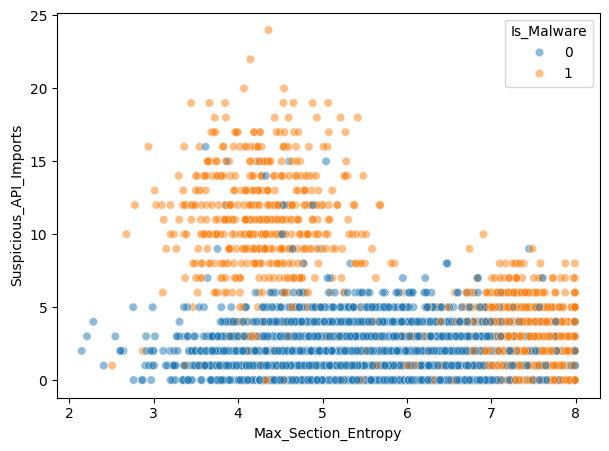

In [4]:
# TASK 2: inspect the suspicious ratio values and feature distributions.
# TODO: count 99999.0 values; visualize Max_Section_Entropy vs Suspicious_API_Imports,
# using Is_Malware as the hue.
import seaborn as sns
print("Sentinel 99999.0 count:", (df_pe.Virtual_to_Raw_Size_Ratio == 99999.0).sum())
print("Corr(VT_PostScan_Detections, Is_Malware):", df_pe.VT_PostScan_Detections.corr(df_pe.Is_Malware))
plt.figure(figsize=(7,5))
sns.scatterplot(data=df_pe, x="Max_Section_Entropy", y="Suspicious_API_Imports",
                hue="Is_Malware", alpha=.5)
plt.show()

In [5]:
# TASK 3: define the target and clean feature matrix.
# TODO: drop SHA256_File_ID, VT_PostScan_Detections and Is_Malware from X.
# TODO: replace impossible Virtual_to_Raw_Size_Ratio == 99999.0 with np.nan.
# Keep the target y separate.
y = df_pe["Is_Malware"]
X = df_pe.drop(columns=["SHA256_File_ID", "VT_PostScan_Detections", "Is_Malware"]).copy()
X["Virtual_to_Raw_Size_Ratio"] = X["Virtual_to_Raw_Size_Ratio"].replace(99999.0, np.nan)

**Answer 1 :**


*   Shape: 6,000 rows × 15 columns (1 identifier, 12 features, 1 post-scan field, 1 target).
*   Class balance: 4,389 benign (0) and 1,611 malware (1), so malware prevalence is 26.85%.
*   Missing values: Import_Count 229 (3.8%), Resource_Entropy 289 (4.8%), all other columns 0.
*   Duplicates: 0 full-row duplicates and 0 duplicates when the ID is excluded. All 6,000 IDs are unique.
Summary statistics: Virtual_to_Raw_Size_Ratio has mean 984.9 and max 99,999, which is not plausible. Max_Section_Entropy ranges from 2.15 to 7.99.

**Answer 2 :**
*   SHA256_File_ID is a unique file identifier (6,000 unique values for 6,000 rows). It carries no generalizable information about a new file, so a model could only memorize it, and it would be meaningless on unseen files.
*   VT_PostScan_Detections is recorded after a scan by external engines, so it is not available when the file is first inspected. It is also target leakage. In this run malware always has 18 to 67 detections and benign files 0 to 2. The correlation with the target is 0.927, and the simple rule VT >= 3 classifies all 6,000 rows correctly, an accuracy of 100%. A model using it would look perfect in the lab and would not work at the decision time.

**Answer 3 :**

59 rows (about 1%) contain the sentinel value 99999.0: 48 benign and 11 malware.
With the sentinel, the mean ratio is 984.9. Without it, the mean is 1.58, the median is 1.13 and the maximum is 6.50, so 99999.0 is physically implausible and clearly a parser error.
Decision: replace 99999.0 with np.nan in X, and let the median imputer inside each CV pipeline fill it. I do not drop the rows, because that would lose 59 files, and in production a parser failure must still produce a prediction.

**Answer 4 :**
*   Max_Section_Entropy vs target is not monotonic: the malware rate is 38% for entropy ≤ 4.0, only 5–7% between 5.0 and 6.5, and 74% above 7.0. Malware appears at both extremes, with benign files concentrated in the middle.
*   Suspicious_API_Imports vs target increases: malware rate 9.7% at 0 APIs, 76.7% for 6–8, and about 96% above 8.
*   The scatter plot shows a cluster of malware with low-to-mid entropy (about 3–6) and many suspicious APIs (about 8–20), and another group at high entropy (about 7–8) with APIs mostly in the 0–8 range. Benign files are mostly at low API counts across all entropy values.
*   Interpretation: on these two features alone, one linear boundary would struggle, since malware sits at both ends of the entropy axis. I do not claim this proves the full 12-feature problem is non-linear.


## Phase 2 — Design a leakage-safe evaluation protocol

Use a stratified 80/20 development/test split. The test set is a lockbox and must not be used for model selection or threshold tuning.

Within the development set, compare models using 5-fold stratified cross-validation. All learned preprocessing (imputation and scaling) must be inside each pipeline so it is refitted separately in each training fold.

### Tasks
1. Create `X_dev`, `X_test`, `y_dev`, `y_test`.
2. Define a preprocessing pipeline with median imputation. Use `RobustScaler` for Logistic Regression; explain why scaling is generally unnecessary for tree models.
3. Build candidate pipelines:
   - Logistic Regression (linear baseline)
   - Deep Decision Tree (single white-box tree)
   - Random Forest (bagging)
   - LightGBM if installed; otherwise `HistGradientBoostingClassifier` and label it accurately (not LightGBM).
4. Use the same CV folds and report train F1, validation F1, PR-AUC and fit time.
5. Interpret bias/variance and choose candidates worth further investigation.

In [6]:
# TODO: stratified development/test split.
# TODO: define pipelines using SimpleImputer(strategy="median").
# RobustScaler should be used for Logistic Regression only.
# --- Split ---
X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED)

# --- Boosting: LightGBM if installed, otherwise an honestly named fallback ---
try:
    from lightgbm import LGBMClassifier
    boost_name = "LightGBM"
    boost = LGBMClassifier(n_estimators=300, learning_rate=0.05, random_state=SEED, verbose=-1)
except ImportError:
    from sklearn.ensemble import HistGradientBoostingClassifier
    boost_name = "HistGradientBoosting (not LightGBM)"
    boost = HistGradientBoostingClassifier(random_state=SEED)

imp = lambda: SimpleImputer(strategy="median")
models = {
  "Logistic Regression": Pipeline([("imp", imp()), ("sc", RobustScaler()),
                                   ("clf", LogisticRegression(max_iter=1000, random_state=SEED))]),
  "Decision Tree (deep)": Pipeline([("imp", imp()), ("clf", DecisionTreeClassifier(random_state=SEED))]),
  "Random Forest": Pipeline([("imp", imp()),
                             ("clf", RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1))]),
  boost_name: Pipeline([("imp", imp()), ("clf", clone(boost))]),
}
models["Stacking"] = Pipeline([("imp", imp()), ("clf", StackingClassifier(
    estimators=[("lr", Pipeline([("sc", RobustScaler()), ("lr", LogisticRegression(max_iter=1000))])),
                ("rf", RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)),
                ("gb", clone(boost))],
    final_estimator=LogisticRegression(max_iter=1000), cv=5, n_jobs=-1))])

In [7]:
# TODO: define StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED).
# TODO: define candidate models and evaluate using cross_validate.
# Suggested scoring: f1 and average_precision.
# Record mean train F1, mean validation F1, validation PR-AUC and fit time.
# --- Same folds for every model ---
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
rows = []
for name, m in models.items():
    r = cross_validate(m, X_dev, y_dev, cv=cv, return_train_score=True,
                       scoring={"f1": "f1", "ap": "average_precision"})
    rows.append({"Model": name, "Train F1": r["train_f1"].mean(), "Val F1": r["test_f1"].mean(),
                 "Val PR-AUC": r["test_ap"].mean(), "Fit time (s)": r["fit_time"].mean(),
                 "F1 gap": r["train_f1"].mean() - r["test_f1"].mean()})
cv_table = pd.DataFrame(rows).set_index("Model").round(4)
display(cv_table)

,Train F1,Val F1,Val PR-AUC,Fit time (s),F1 gap
Model,,,,,
Logistic Regression,0.9231,0.9238,0.9080,0.0288,-0.0007
Decision Tree (deep),1.0000,0.8301,0.7330,0.0687,0.1699
Random Forest,1.0000,0.9237,0.9054,2.8526,0.0763
LightGBM,0.9979,0.9217,0.9033,0.4178,0.0762
Stacking,0.9576,0.9244,0.9087,19.0944,0.0332


**Answer 2 :**

Median imputation is inside every pipeline. RobustScaler is used only for Logistic Regression and for the logistic base learner of Stacking. Scaling is generally unnecessary for trees because they split on thresholds of one feature at a time, so a monotonic rescaling of a feature does not change the splits.

**Answer 5 :**

***Observed (from the CV table)***:

*   The deep Decision Tree overfits most: train F1 = 1.000, validation F1 = 0.830, gap = 0.170, PR-AUC = 0.733 (lowest by a wide margin).
*   Random Forest and LightGBM also have train F1 near 1.0 (1.000 and 0.998) with gaps of about 0.076, but validation F1 (0.924 and 0.922) is far above the single tree’s.
*   Logistic Regression has a gap of about 0 (−0.0007), with validation F1 = 0.924 and PR-AUC = 0.908.
*   Logistic Regression, Random Forest, LightGBM and Stacking are close: validation F1 0.922–0.924, PR-AUC 0.903–0.909.

*   Stacking has the highest mean validation F1 (0.9244) but takes 17.1 s to fit, versus 0.03 s for Logistic Regression.

***Interpretation:***


*   The single tree has high variance (overfitting). Bagging
(Random Forest) and boosting reduce this variance strongly.
*   Logistic Regression has low variance and is already competitive. This suggests that, on these 12 features, a nearly linear boundary works well. This does not contradict the Phase 1 two-feature plot, which showed only two of the 12 features.
*   The differences among the four leading models (about 0.006 in PR-AUC) are small compared with typical fold-to-fold variation, so the table alone does not identify a clear winner.
*   Stacking’s gain over Logistic Regression (+0.0006 F1) is negligible compared with its cost, so the extra complexity is not justified.

***Recommendation:***
Keep Logistic Regression (fast, simple, interpretable baseline), LightGBM and Random Forest (tree models supported by TreeSHAP for Phase 3).
Drop the single Decision Tree (overfits) and Stacking (no measurable gain for its cost).

### Decision checkpoint 1 — Select a shortlist

Answer with evidence from your table:
1. Which model shows the largest train–validation gap? What does it suggest?
2. Does the linear baseline already perform competitively?
3. Does Random Forest improve on the single tree?
4. Does boosting improve PR-AUC enough to justify its complexity?
5. Is stacking justified by the measured gain, runtime and deployment context? Do not assume that a more complex model must win.

**AtlasPay operating constraint:** the service receives about 12,000 PE files/day, while the 6-person SOC wants no more than 120 model-generated review alerts/day. Treat this as a queue-capacity constraint to test—not as a result guaranteed by the synthetic dataset. Training time matters during model updates; inference latency matters during scanning. These are separate measurements.

1. The deep Decision Tree: train F1 1.000 vs validation F1 0.830, gap 0.170. This suggests it memorizes the training data (high variance, overfitting) and generalizes poorly. Its PR-AUC (0.733) is also the lowest.
2. Yes. Logistic Regression has validation F1 0.9238 and PR-AUC 0.9080, with a gap of about 0 (−0.0007). It is within 0.001 of the best F1 (Stacking, 0.9244) and its PR-AUC is within 0.001 of the best (0.9087). Interpretation: on these 12 synthetic features, a nearly linear boundary works well, so a more complex model must prove it adds value.
3. Yes, clearly. Validation F1 rises from 0.830 to 0.924 and PR-AUC from 0.733 to 0.905, while the gap falls from 0.170 to 0.076. Averaging many trees reduces the variance of a single deep tree. Random Forest is still not better than Logistic Regression (F1 0.9237 vs 0.9238).
4. No, not on PR-AUC alone. LightGBM has PR-AUC 0.9033, slightly below Logistic Regression (0.9080) and Random Forest (0.9054), and a larger gap (0.076). The difference (about 0.005) is small relative to fold-to-fold variation, so I do not claim LightGBM is worse. I would keep it only because TreeSHAP supports it for the Phase 3 explanations and because it fits faster (0.34 s) than Random Forest (2.79 s), not because of accuracy.
5. No. Stacking has the highest mean validation F1 (0.9244) and PR-AUC 0.9087, but the gain over Logistic Regression is +0.0006 F1 and +0.0007 PR-AUC, far inside fold-to-fold noise. It takes 17.1 s to fit versus 0.03 s (about 500 times slower), and at scoring time it must run three base models plus a meta-model. A more complex model does not have to win, and here the measured gain does not justify the runtime, the maintenance or the extra attack surface.

In [8]:
# TODO: measure prediction latency for shortlisted fitted models.
# Use repeated batch predictions; report milliseconds per 1,000 files
# and document hardware/runtime limitations.
import os, platform

SHORTLIST = ["Logistic Regression", boost_name, "Random Forest"]
fitted = {n: clone(models[n]).fit(X_dev, y_dev) for n in SHORTLIST}   # fit on X_dev only

def latency_ms_per_1000(model, Xb, reps=30, warmup=3):
    for _ in range(warmup):                       # warm-up runs, not timed
        model.predict_proba(Xb)
    ts = []
    for _ in range(reps):
        t0 = time.perf_counter()
        model.predict_proba(Xb)
        ts.append(time.perf_counter() - t0)
    ts = np.array(ts)
    # seconds per file * 1e6 = milliseconds per 1,000 files
    return np.median(ts) / len(Xb) * 1e6, np.percentile(ts, 95) / len(Xb) * 1e6

rows = []
for n, f in fitted.items():
    med, p95 = latency_ms_per_1000(f, X_test)
    rows.append({"Model": n, "ms/1000 files (median)": round(med, 2), "ms/1000 files (p95)": round(p95, 2)})
display(pd.DataFrame(rows).set_index("Model"))
print("Batch size:", len(X_test), "| CPU count:", os.cpu_count(), "|", platform.platform())

,ms/1000 files (median),ms/1000 files (p95)
Model,,
Logistic Regression,1.72,1.91
LightGBM,34.17,38.52
Random Forest,100.38,113.51


Batch size: 1200 | CPU count: 2 | Linux-6.6.159+-x86_64-with-glibc2.39


## Phase 3 — Error forensics: investigate a real disagreement

Choose a held-out test observation for which the candidate models disagree. Do not hard-code a story before verifying the predictions.

### Tasks
1. Generate probabilities for the same test observations from Logistic Regression and your selected tree ensemble.
2. Find a malware observation where Logistic Regression predicts benign at the chosen illustrative threshold while the tree model predicts malware. If no such observation exists, report that honestly and choose another meaningful disagreement.
3. Print the ground-truth label, feature values, probabilities and predictions.
4. Build global and local SHAP explanations for a supported tree model.
5. Interpret a beeswarm and a local waterfall. Explain why SHAP is not causal evidence.

In [9]:
# TODO: fit shortlisted models on X_dev only, then predict probabilities on X_test.
# TODO: find and VERIFY a disagreement. Use threshold=0.50 for this diagnostic only.
# Never label a prediction "missed" or "caught" without checking y_true and y_pred.
TREE = "LightGBM"          # ou boost_name, c'est ton modèle à arbres choisi
fitted = {n: clone(models[n]).fit(X_dev, y_dev) for n in ["Logistic Regression", TREE]}  # X_dev seulement

p_lr   = fitted["Logistic Regression"].predict_proba(X_test)[:, 1]
p_tree = fitted[TREE].predict_proba(X_test)[:, 1]
yt = y_test.values
pl, pt = p_lr >= 0.50, p_tree >= 0.50      # seuil 0.50 : diagnostic seulement

# Compter TOUS les types de désaccord avant de choisir une histoire
print("A malware : LR benin,   arbre malware:", int(((yt==1) & ~pl &  pt).sum()))
print("B malware : LR malware, arbre benin  :", int(((yt==1) &  pl & ~pt).sum()))
print("C benin   : LR malware, arbre benin  :", int(((yt==0) &  pl & ~pt).sum()))
print("D benin   : LR benin,   arbre malware:", int(((yt==0) & ~pl &  pt).sum()))
print("Total desaccords:", int((pl != pt).sum()), "sur", len(yt))

mask = (yt == 1) & ~pl & pt                 # type A, demande par l'enonce
if mask.sum() == 0:
    print("Aucun cas A : choisir B, C ou D et le dire honnetement.")
else:
    i = int(np.where(mask)[0][0])           # position dans X_test
    case_idx = X_test.index[i]              # index d'origine
    print("\nIndex d'origine:", case_idx, "| ID:", df_pe.loc[case_idx, "SHA256_File_ID"])
    print("Verite terrain y_true:", yt[i])
    print(f"LR   : p = {p_lr[i]:.3f} -> prediction {int(pl[i])}")
    print(f"{TREE}: p = {p_tree[i]:.3f} -> prediction {int(pt[i])}")
    display(X_test.iloc[[i]].T)

A malware : LR benin,   arbre malware: 1
B malware : LR malware, arbre benin  : 2
C benin   : LR malware, arbre benin  : 0
D benin   : LR benin,   arbre malware: 1
Total desaccords: 4 sur 1200

Index d'origine: 5115 | ID: sha256_05115_pe
Verite terrain y_true: 1
LR   : p = 0.426 -> prediction 0
LightGBM: p = 0.991 -> prediction 1


,5115
Max_Section_Entropy,7.221465
Import_Count,13.184508
Suspicious_API_Imports,1.000000
Has_Valid_Signature,0.000000
Has_RWX_Section,0.000000
Virtual_to_Raw_Size_Ratio,2.330997
Resource_Entropy,5.381376
Num_Embedded_URLs_IPs,1.000000
Abnormal_Compile_Timestamp,0.000000
Num_Sections,10.000000


**Observed**:

*   Out of 1,200 test files, the two models disagree on only 4 at threshold 0.50.
Type A (malware: LR benign, LightGBM malware): 1,
Type B (malware: LR malware, LightGBM benign): 2,
Type C (benign: LR malware, LightGBM benign): 0,
Type D (benign: LR benign, LightGBM malware): 1.
*   A type A case exists, so the requested disagreement is available. Selected case: row 5115 (sha256_05115_pe), y_true = 1.
*   Logistic Regression: p = 0.426 → predicts benign (0). LightGBM: p = 0.991 → predicts malware (1). Since y_true = 1, the LightGBM prediction is correct and the Logistic Regression prediction is a false negative at this diagnostic threshold.
*   Features: Max_Section_Entropy 7.22, Virtual_to_Raw_Size_Ratio 2.33, Num_Sections 10, Has_Valid_Signature 0, Import_Count 13.2, Suspicious_API_Imports 1, Has_RWX_Section 0, Num_Embedded_URLs_IPs 1, Export_Count 1.

**Interpretation:**
The two models mostly agree (4 of 1,200 disagreements), so this is an edge case, not a general pattern. Logistic Regression’s p = 0.426 is close to the 0.50 line, whereas LightGBM is very confident (0.991).

Disagreements do not show that the tree is better overall: in the 4 disagreements, LightGBM is correct in 1 (type A) and wrong in 3 (the 2 type B malware missed and the 1 type D false alarm), so Logistic Regression is correct in 3 of them.



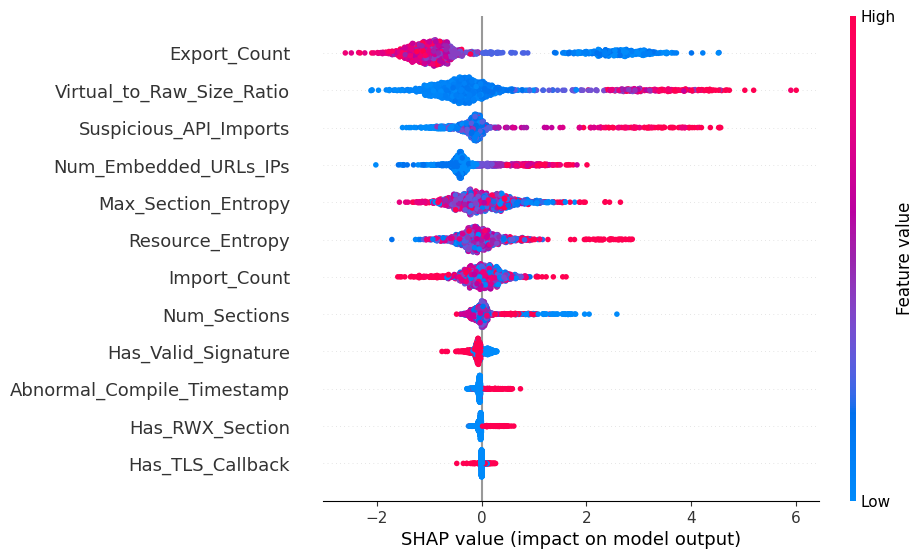

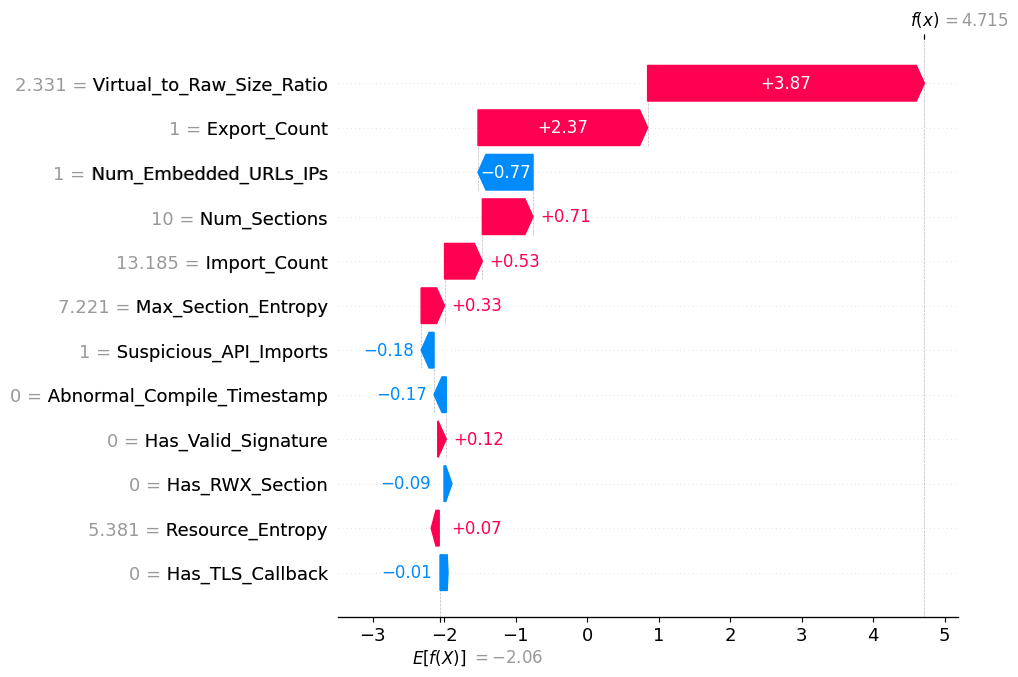

Base value: -2.0602948654864304
Top 3 vers malware:
 Virtual_to_Raw_Size_Ratio    3.871
Export_Count                 2.372
Num_Sections                 0.708
dtype: float64
Top 2 vers benin:
 Num_Embedded_URLs_IPs    -0.769
Suspicious_API_Imports   -0.180
dtype: float64


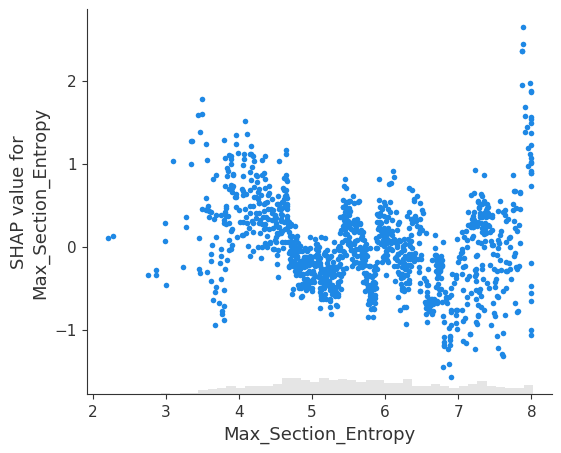

In [10]:
# TODO: install/import shap if needed.
# TODO: use shap.TreeExplainer with a supported fitted tree model.
# TODO: produce global beeswarm and local waterfall for the verified case.
# Optional: dependence plot for Max_Section_Entropy.
# pip install shap   (une seule fois)
import shap

tree_pipe = fitted[TREE]
Xt = pd.DataFrame(tree_pipe[:-1].transform(X_test),      # apres imputation (pipeline deja ajuste sur X_dev)
                  columns=X_test.columns, index=X_test.index)

explainer = shap.TreeExplainer(tree_pipe[-1])
sv = explainer(Xt)
if sv.values.ndim == 3:                  # certains modeles renvoient les 2 classes
    sv = sv[:, :, 1]                     # on garde la classe malware

shap.plots.beeswarm(sv, max_display=12)             # explication globale
shap.plots.waterfall(sv[i], max_display=12)         # explication locale du cas verifie

# Resume ecrit du cas
contrib = pd.Series(sv.values[i], index=Xt.columns).sort_values()
print("Base value:", float(np.ravel(sv.base_values[i])[0]))
print("Top 3 vers malware:\n", contrib.tail(3)[::-1].round(3))
print("Top 2 vers benin:\n",  contrib.head(2).round(3))

# Optionnel
shap.plots.scatter(sv[:, "Max_Section_Entropy"])

1. Global beeswarm

**Observed :**
*   Features are ranked by mean |SHAP|: Export_Count, Virtual_to_Raw_Size_Ratio, Suspicious_API_Imports, Num_Embedded_URLs_IPs, Max_Section_Entropy, Resource_Entropy, Import_Count, Num_Sections, then the four binary flags (smallest spread).
*   Low Export_Count (blue) gives positive SHAP (about +1.5 to +4.5); high values give negative SHAP. High Virtual_to_Raw_Size_Ratio (red) has a long positive tail up to about +6, while most files are near 0.
*   High Suspicious_API_Imports, Num_Embedded_URLs_IPs and Resource_Entropy push toward malware; low Import_Count pushes toward malware. A valid signature lowers the score, while an abnormal timestamp and an RWX section raise it.
*   Max_Section_Entropy and Num_Sections show red and blue points on both sides of zero.

**Interpretation :**
The model relies mainly on export count, size ratio, suspicious APIs and embedded URLs; the binary flags matter less.
The mixed colors for entropy and number of sections show that these features are not “higher = more suspicious”, which motivates the dependence plot below.

2. Local waterfall (test row 5115, y_true = 1)

**Observed :**

*  Base value E[f(X)] = −2.06; final output f(x) ≈ +4.72, i.e. p ≈ 0.991 for malware. The 12 contributions sum to +6.78.
*   Dominant contributions: Virtual_to_Raw_Size_Ratio = 2.331 (+3.87) and Export_Count = 1 (+2.37). Smaller: Num_Sections = 10 (+0.71), Import_Count = 13.2 (+0.53), Max_Section_Entropy = 7.22 (+0.33).
*   Negative: Num_Embedded_URLs_IPs = 1 (−0.77), Suspicious_API_Imports = 1 (−0.18), Abnormal_Compile_Timestamp = 0 (−0.17).

**Interpretation :** The score for this file comes mostly from two features, which are also the two strongest directions in the beeswarm, so the file follows the model’s main learned pattern. The benign-looking values (1 URL, 1 suspicious API, no RWX section) lowered the output slightly but did not change the prediction.

Logistic Regression scored this file 0.426 (below 0.50) and missed it, while LightGBM gave 0.991.

3. Why SHAP is not causal evidence

*   SHAP decomposes the model’s output; it describes how the model behaves, not how the world works. A large contribution from Virtual_to_Raw_Size_Ratio does not mean this ratio makes a file malicious.
*   Attributions depend on the model and the background data, and correlated features share credit, so the ranking is not a ranking of real causes (for example, Suspicious_API_Imports looked strongly separating in Phase 1 but ranks third here).
*   A SHAP value compares a feature value with the average prediction; no intervention or counterfactual was run.
*   The data are synthetic and rule-generated, so patterns like “few exports → malware” reflect that generator, not real malware families. A real benign packed installer can have high entropy or a large size ratio.
*   A score of 0.991 with a clear explanation is not proof of malice: labels in this dataset contain noise, and the model can be wrong.


## Phase 4 — Translate model scores into a SOC decision

For the AtlasPay teaching scenario, the SOC supplies these *illustrative planning assumptions* (not measured company costs):

- False positive (FP): $25 per alert (analyst investigation and workflow friction).
- False negative (FN): $500 per missed malicious file (expected response/remediation cost).
- A future inline-blocking scenario may raise FP cost to $2,000 because blocking a legitimate vendor update or payment-support executable could interrupt operations.

\[
C(\tau)=25\,FP(\tau)+500\,FN(\tau)
\]

### Critical protocol
Select the threshold using development data only (for example, out-of-fold development predictions). Freeze the selected threshold. Evaluate it once on the lockbox test set. Never search test thresholds and report the minimum as final performance.

### Tasks
1. Generate out-of-fold probabilities for each shortlisted model on the development set.
2. Find the cost-minimizing threshold on those OOF predictions.
3. Freeze the threshold and evaluate FP, FN, precision, recall and cost on the test set.
4. Repeat threshold selection under `C_FP = $2,000` using development predictions. Explain why the preferred threshold changes.
5. Discuss the limitations of the cost assumptions and whether the dataset prevalence represents the intended deployment environment.

**Capacity check:** Compare the number of test-set alerts at your frozen threshold with the scenario’s 120-alert/day target only as an indicative exercise. The test set is a sample, the dataset prevalence is synthetic, and a simple test-set count must not be presented as a validated daily alert forecast. Explain what real telemetry and calibration would be required.

In [11]:
# TODO: define COST_FP=25 and COST_FN=500.
# TODO: generate OOF development probabilities; optimize threshold on OOF only.
# TODO: freeze threshold and evaluate once on X_test.
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import confusion_matrix

COST_FP, COST_FN = 25, 500
SHORT = ["Logistic Regression", boost_name, "Random Forest"]   # boost_name = "LightGBM" chez vous
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
grid = np.round(np.arange(0.01, 1.00, 0.01), 2)
yd, yt = y_dev.values, y_test.values

def cost_curve(y, p, cfp, cfn):
    out = []
    for t in grid:
        pred = p >= t
        fp = int((pred & (y == 0)).sum()); fn = int((~pred & (y == 1)).sum())
        out.append(cfp * fp + cfn * fn)
    return np.array(out)

def pick(curve):                      # si plusieurs seuils ont le meme cout minimal : mediane
    ties = grid[curve == curve.min()]
    return float(np.median(ties)), len(ties), int(curve.min())

# 1) Probabilites hors-pli (OOF) sur le dev uniquement
oof = {n: cross_val_predict(clone(models[n]), X_dev, y_dev, cv=cv, method="predict_proba")[:, 1] for n in SHORT}

# 2) + 4) Seuils choisis sur OOF, pour les deux scenarios, puis GELES
frozen = {}
for scen, cfp in [("triage", COST_FP), ("blocking", 2000)]:
    print(f"\n{scen}: C_FP={cfp}, C_FN={COST_FN}, seuil theorique={cfp/(cfp+COST_FN):.3f}")
    for n in SHORT:
        t, nties, best = pick(cost_curve(yd, oof[n], cfp, COST_FN))
        frozen[(scen, n)] = t
        print(f"  {n:38s} t*={t:.2f} (egalites={nties}) cout OOF={best}")

# 3) Evaluation UNIQUE sur le coffre-fort, avec les seuils geles
fit = {n: clone(models[n]).fit(X_dev, y_dev) for n in SHORT}
ptest = {n: fit[n].predict_proba(X_test)[:, 1] for n in SHORT}
rows = []
for (scen, n), t in frozen.items():
    cfp = COST_FP if scen == "triage" else 2000
    pred = (ptest[n] >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(yt, pred).ravel()
    rows.append(dict(scenario=scen, model=n, thr=t, TP=tp, FP=fp, FN=fn, TN=tn,
                     precision=round(tp/max(tp+fp, 1), 3), recall=round(tp/(tp+fn), 3),
                     cost=cfp*fp + COST_FN*fn, alerts=int(pred.sum()), alert_rate=round(pred.mean(), 3)))
display(pd.DataFrame(rows))

# References simples (labels seulement, aucun seuil cherche sur le test)
npos, nneg = int((yt == 1).sum()), int((yt == 0).sum())
print("Rien signaler :", COST_FN*npos, "| Tout signaler (triage) :", COST_FP*nneg, "| Tout signaler (blocage) :", 2000*nneg)
print("Alertes d'un detecteur parfait sur 12 000 fichiers, a la prevalence du dev :", round(yd.mean()*12000))


triage: C_FP=25, C_FN=500, seuil theorique=0.048
  Logistic Regression                    t*=0.28 (egalites=1) cout OOF=72225
  LightGBM                               t*=0.12 (egalites=1) cout OOF=72325
  Random Forest                          t*=0.33 (egalites=1) cout OOF=72800

blocking: C_FP=2000, C_FN=500, seuil theorique=0.800
  Logistic Regression                    t*=0.50 (egalites=1) cout OOF=152500
  LightGBM                               t*=0.65 (egalites=5) cout OOF=157000
  Random Forest                          t*=0.70 (egalites=2) cout OOF=151500


,scenario,model,thr,TP,FP,FN,TN,precision,recall,cost,alerts,alert_rate
0,triage,Logistic Regression,0.280,288,10,34,868,0.966,0.894,17250,298,0.248
1,triage,LightGBM,0.120,288,26,34,852,0.917,0.894,17650,314,0.262
2,triage,Random Forest,0.330,288,12,34,866,0.960,0.894,17300,300,0.250
3,blocking,Logistic Regression,0.500,286,8,36,870,0.973,0.888,34000,294,0.245
4,blocking,LightGBM,0.650,283,8,39,870,0.973,0.879,35500,291,0.242
5,blocking,Random Forest,0.705,282,8,40,870,0.972,0.876,36000,290,0.242


Rien signaler : 161000 | Tout signaler (triage) : 21950 | Tout signaler (blocage) : 1756000
Alertes d'un detecteur parfait sur 12 000 fichiers, a la prevalence du dev : 3222


*   The three models have the same recall (0.894) and the same 34 FN; they differ
only in false positives, which make up at most about 400 of the cost (16 FPs × 25). With the OOF costs also within 1% of each other (72,225 to 72,800), the models are practically tied under the triage costs.
*   Model choice must rest on development evidence and operational criteria, not on the lockbox result. By OOF cost, Logistic Regression is nominally lowest (and the simplest and fastest), so I would select it for triage, keeping LightGBM as a challenger.
*   The gain over “flag everything” is modest (about 20%) because a 20:1 cost ratio and a 27% prevalence make flagging many files cheap in this synthetic setting.

4.   
**Observed :**

*   Under C_FP = 2000, the frozen thresholds rise: Logistic Regression 0.28 → 0.50, LightGBM 0.12 → 0.65, Random Forest 0.33 → 0.705.
*   On the lockbox: FP falls to 8 for all three models (from 10, 26 and 12), FN rises to 36, 39 and 40 (from 34), and cost is 34,000, 35,500 and 36,000. The 8 FP alone cost 16,000, almost half of each total.

**Interpretation :**

*   For calibrated probabilities, flag a file when p > C_FP/(C_FP + C_FN): 25/525 ≈ 0.048 for triage and 2000/2500 = 0.80 for blocking. When a false alarm becomes 80 times more expensive than a miss in relative terms, the model must be more confident before acting, so the preferred threshold rises and recall falls slightly (0.894 → 0.876–0.888).
*   All frozen thresholds are well above the theoretical ones (for example 0.28 vs 0.048). Possible reasons are imperfect calibration, label noise (about 4%), and a cost curve that is flat near its minimum, as the ties for LightGBM (5) and Random Forest (2) show. The thresholds are not precisely identified and should not be reported to more than about one decimal of confidence.


5.  
**Limits of the cost assumptions :**

Costs are illustrative. A cost of 25 applies only to FP, but in triage each alert, true or false, takes analyst time. A missed file does not always cost 500. The costs ignore queue capacity, analyst fatigue and delay. A sensitivity analysis over several cost ratios would be needed.

The test set contains only 322 malware files; 34 FN make up 98.5% of the triage cost, so a few files change the result noticeably.

Prevalence is 26.85% by construction of the generator and is unlikely to represent AtlasPay’s incoming PE files. Development and test sets come from the same generator, so drift and adversarial adaptation are not tested.

**Capacity check :**

*   Observed: at the frozen triage thresholds, the test set produced 298 (LR), 314 (LightGBM) and 300 (RF) alerts out of 1,200 files, i.e. 24.8–26.2%. The scenario target is 120 alerts for 12,000 files, i.e. 1%. A perfect detector at the synthetic prevalence would flag about 3,222 files of 12,000.
*   Interpretation: the target cannot be met at this prevalence, even by a perfect detector. This shows the dataset does not look like AtlasPay’s traffic; it is not a verdict on the model.
*   Illustration (assumes recall and false-positive rate stay as measured, which is untested): LR’s FP rate on the test benign files is 10/878 = 1.14%. At 12,000 files per day, that alone is about 137 false alerts, more than 120, and at 1% prevalence precision would fall to about 0.44 (from 0.966) with about 243 alerts. Reaching 120 alerts/day would require a much lower FP rate and/or a very low real prevalence.
*   Missing evidence: real AtlasPay submissions with analyst-confirmed labels over time, a temporal split, an estimate of true prevalence and its daily variation, calibration checks (reliability curve, recalibration), then validation in shadow mode.















## Phase 5 — Final architecture decision: CISO recommendation

Write a concise recommendation (approximately 1 page) answering:

1. What is AtlasPay’s business use case, what is the positive class, and why is the initial deployment analyst-assisted rather than autonomous blocking?
2. Which candidate do you recommend for the *perimeter scanning* scenario, and why?
3. What threshold do you recommend under the supplied cost assumptions?
4. What evidence supports the choice: PR-AUC, recall, precision, FP/FN, cost, latency and explainability?
5. Does the proposed alert volume appear compatible with the 120-alert/day planning target? What evidence is missing for a reliable daily forecast? What changes for inline blocking, where a false positive could interrupt payment-support operations?
6. What are the key risks before production: synthetic-to-real gap, label noise, prevalence shift, data drift, calibration, adversarial adaptation, analyst workflow and monitoring?


**Submission rule:** report the outputs you actually obtained. Do not copy expected results or describe synthetic patterns as universal malware signatures.

**1.** **Use case and deployment mode:** The model scores each Windows PE file at first inspection (before execution) so that SOC analysts review the most suspicious files first. The positive class is malware (Is_Malware = 1). Recommendation: start as analyst-assisted triage, not automatic blocking, because a false positive could block a legitimate vendor update or payment-support tool, and the evidence here is synthetic and not validated on AtlasPay data.

**2. Recommended model:** Logistic Regression (median imputation + RobustScaler) for perimeter scanning. Observed: in 5-fold CV, validation PR-AUC was 0.908 (LightGBM 0.903, Random Forest 0.905) and validation F1 0.924 (0.922, 0.924), with a train–validation gap near 0 (−0.0007); the deep tree overfit (gap 0.170, PR-AUC 0.733) and Stacking gained +0.0006 F1 for a 17.1 s fit versus 0.03 s. Interpretation: the top models are tied within fold-to-fold noise, so I select the simplest, fastest and most transparent one. LightGBM stays as a challenger (shadow mode), since SHAP showed non-monotonic effects such as entropy that a linear model cannot capture, even though CV showed no measurable gain.

**3. Threshold:** 0.28, selected on development out-of-fold predictions (minimum cost 72,225 under C_FP = 25, C_FN = 500) and frozen before touching the lockbox. The curve is flat and the theoretical threshold is 0.048, so this value is not precisely identified. At this threshold the model flags row 5115, which Logistic Regression had missed at the diagnostic threshold of 0.50 (p = 0.426).

**4. Evidence:** TP 288, FP 10, FN 34, precision 0.966, recall 0.894, cost 17,250, versus 21,950 for flagging every file and 161,000 for flagging none. The three shortlisted models have identical recall (0.894) and differ only by 16 FP (cost difference ≤ 400), so the cost does not separate them. Explainability: coefficients are directly inspectable; for LightGBM, TreeSHAP gave attributions (e.g. size ratio +3.87 and export count +2.37 for row 5115), which describe the model, not causes. Fit time: 0.03 s (LR), 0.34 s (LightGBM), 2.8 s (Random Forest).

**5. Alert volume:** Observed: 298 alerts out of 1,200 test files (24.8%), against a target of 120 per 12,000 (1%). Even a perfect detector at the synthetic prevalence (26.85%) would flag about 3,222 of 12,000 files. Interpretation: the target cannot be tested with this dataset; its prevalence is not representative. Illustration (assumes the measured FP rate of 1.14% transfers, which is untested): false alarms alone would be about 137 per 12,000 files. Missing evidence: real submissions with analyst-confirmed labels, temporal split, true prevalence and its variation, calibration, shadow-mode run. Inline blocking: with C_FP = 2,000 the frozen Logistic Regression threshold rises to 0.50 (FP 8, FN 36, precision 0.973, recall 0.888, cost 34,000); even 8 blocked benign files (0.9% of benign test files) is not acceptable without safeguards. Not recommended now.

**6. Key risks before production**: Synthetic-to-real gap (patterns come from the generator, not real malware families); label noise (about 4% flipped labels by construction, which limits achievable FN/FP); prevalence shift (precision and alert count change sharply at lower real prevalence); data drift (no temporal test); calibration (probabilities not verified; thresholds far from the theoretical value); adversarial adaptation (packing or padding can alter static features); analyst workflow (queue, fatigue, feedback loop); monitoring (alert rate, precision from analyst verdicts, feature drift).






